In [ ]:
# ==========================================
# Step 1 : Install Required Libraries
# ==========================================

!pip -q install diffusers transformers accelerate peft safetensors
!pip -q install icrawler
!pip -q install ftfy
!pip -q install xformers
!pip -q install pillow matplotlib tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 25.3 MB/s eta 0:00:00


In [ ]:
# ==========================================
# Step 2 : Import Libraries
# ==========================================

import os
import torch
import matplotlib.pyplot as plt

from PIL import Image
from tqdm import tqdm

print("PyTorch Version :", torch.__version__)
print("CUDA Available :", torch.cuda.is_available())
print("Device :", "GPU" if torch.cuda.is_available() else "CPU")

PyTorch Version : 2.11.0+cu128
CUDA Available : True
Device : GPU


In [ ]:
# ==========================================
# Step 3 : Mount Google Drive
# ==========================================

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ==========================================
# Step 4 : Create Project Folders
# ==========================================

import os

project_path = "/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning"

folders = [
    "artwork_dataset",
    "generated_images",
    "checkpoints",
    "outputs"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("✅ Project folders created successfully!")

✅ Project folders created successfully!


In [ ]:
!pip -q install bing-image-downloader

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/artwork_dataset"

os.makedirs(dataset_path, exist_ok=True)

print("Dataset Folder Ready!")

Dataset Folder Ready!


In [ ]:
# ==========================================
# Step 5C : Download Artwork from The Met (Safe / Family-Friendly Filter)
# ==========================================

!pip -q install requests

import os
import requests
from PIL import Image
from io import BytesIO
from tqdm import tqdm

save_dir = "/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/final_dataset"
os.makedirs(save_dir, exist_ok=True)

# Blocklist of keywords that indicate nudity / mature classical subjects
BLOCKED_KEYWORDS = [
    "nude", "nudity", "naked", "bather", "bathers", "venus", "erotic",
    "odalisque", "reclining figure", "female figure", "male figure",
    "undressed", "topless", "breast", "genital"
]

def is_safe(title, tags):
    text = (title or "").lower() + " " + " ".join(tags or []).lower()
    return not any(keyword in text for keyword in BLOCKED_KEYWORDS)

# Search safer, subject-specific queries instead of generic "painting"
search_queries = [
    "landscape painting",
    "still life painting",
    "portrait painting",
    "seascape painting",
    "architecture painting"
]

search_url = "https://collectionapi.metmuseum.org/public/collection/v1/search"

object_ids = []
for q in search_queries:
    params = {"q": q, "hasImages": "true"}
    response = requests.get(search_url, params=params)
    ids = response.json().get("objectIDs") or []
    object_ids.extend(ids)

# Deduplicate while preserving order
object_ids = list(dict.fromkeys(object_ids))

print(f"Found {len(object_ids)} candidate artworks")

count = 0

for obj_id in tqdm(object_ids):

    if count >= 100:
        break

    try:
        obj = requests.get(
            f"https://collectionapi.metmuseum.org/public/collection/v1/objects/{obj_id}"
        ).json()

        title = obj.get("title", "")
        tags = [t.get("term", "") for t in (obj.get("tags") or [])]

        if not is_safe(title, tags):
            continue

        image_url = obj.get("primaryImageSmall")

        if image_url:
            img = Image.open(BytesIO(requests.get(image_url, timeout=20).content))
            img = img.convert("RGB")
            img.save(f"{save_dir}/artwork_{count:03d}.jpg")
            count += 1

    except:
        pass

print(f"\n✅ Downloaded {count} safe, family-friendly artwork images.")


Found 2775 candidate artworks


100%|██████████| 2775/2775 [02:11<00:00, 21.09it/s]


✅ Downloaded 68 safe, family-friendly artwork images.


In [ ]:
import os

dataset = "/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/final_dataset"

images = [f for f in os.listdir(dataset)
          if f.endswith((".jpg",".jpeg",".png"))]

print("Total Images :", len(images))

Total Images : 281


Total Images: 281


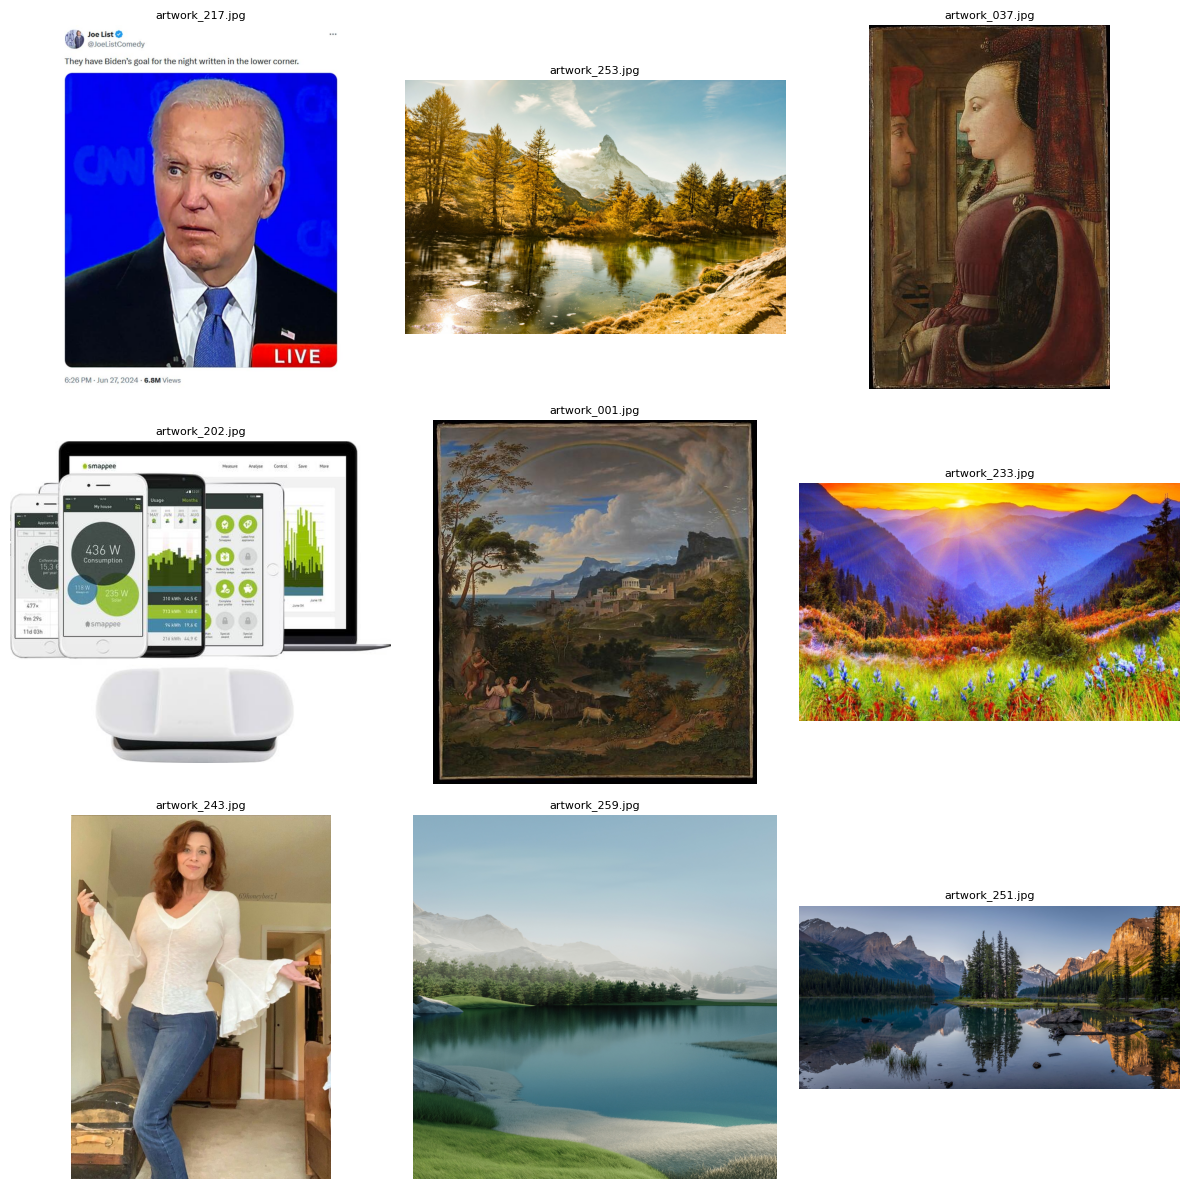

If you still spot an unsuitable image above, delete that file from
/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/final_dataset and re-run this cell.


In [ ]:
# ==========================================
# Step 6 : Visualize Artwork Dataset
# ==========================================

import os
import random
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/final_dataset"

image_files = [f for f in os.listdir(dataset_path)
               if f.lower().endswith((".jpg", ".jpeg", ".png"))]

print(f"Total Images: {len(image_files)}")

plt.figure(figsize=(12,12))

samples = random.sample(image_files, min(9, len(image_files)))

for i, img_name in enumerate(samples):
    img = Image.open(os.path.join(dataset_path, img_name))

    plt.subplot(3,3,i+1)
    plt.imshow(img)
    plt.title(img_name, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("If you still spot an unsuitable image above, delete that file from")
print(dataset_path, "and re-run this cell.")


In [ ]:
# ==========================================
# Step 7.1 : Load BLIP
# ==========================================

from transformers import BlipProcessor, BlipForConditionalGeneration
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base"
).to(device)

print("✅ BLIP Loaded Successfully!")

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

✅ BLIP Loaded Successfully!


In [ ]:
# ==========================================
# Step 7.2 : Generate Captions
# ==========================================

import pandas as pd
from PIL import Image
from tqdm import tqdm

captions = []

for img_name in tqdm(image_files):

    image = Image.open(os.path.join(dataset_path, img_name)).convert("RGB")

    inputs = processor(images=image, return_tensors="pt").to(device)

    output = model.generate(**inputs, max_new_tokens=30)

    caption = processor.decode(output[0], skip_special_tokens=True)

    captions.append({
        "image": img_name,
        "caption": caption
    })

caption_df = pd.DataFrame(captions)

caption_df.to_csv(
    "/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/captions.csv",
    index=False
)

caption_df.head()



  0%|          | 0/281 [00:00<?, ?it/s]

  0%|          | 1/281 [00:03<18:01,  3.86s/it]

  1%|          | 2/281 [00:04<08:54,  1.91s/it]

  1%|          | 3/281 [00:04<05:23,  1.16s/it]

  1%|▏         | 4/281 [00:05<04:04,  1.13it/s]

  2%|▏         | 5/281 [00:05<02:54,  1.58it/s]

  2%|▏         | 6/281 [00:05<02:40,  1.71it/s]

  2%|▏         | 7/281 [00:06<02:37,  1.74it/s]

  3%|▎         | 8/281 [00:06<02:17,  1.98it/s]

  3%|▎         | 9/281 [00:07<02:02,  2.22it/s]

  4%|▎         | 10/281 [00:07<01:53,  2.39it/s]

  4%|▍         | 11/281 [00:07<02:00,  2.25it/s]

  4%|▍         | 12/281 [00:08<02:04,  2.15it/s]

  5%|▍         | 13/281 [00:09<02:33,  1.74it/s]

  5%|▍         | 14/281 [00:09<02:30,  1.77it/s]

  5%|▌         | 15/281 [00:10<02:07,  2.08it/s]

  6%|▌         | 16/281 [00:10<01:54,  2.31it/s]

  6%|▌         | 17/281 [00:11<02:30,  1.75it/s]

  6%|▋         | 18/281 [00:11<02:32,  1.72it/s]

  7%|▋         | 19/281 [00:12<02:31,  1.73it/s]

  7%|▋         |

,image,caption
0,artwork_068.jpg,a painting of a street scene with people sitti...
1,artwork_069.jpg,a painting of a mountain landscape with houses
2,artwork_070.jpg,a painting of sunflowers in a vase
3,artwork_071.jpg,a painting of a woman in a garden
4,artwork_072.jpg,starr night over the rhone


In [ ]:
caption_df.sample(10)

,image,caption
266,artwork_053.jpg,a painting of a landscape with a man and woman...
39,artwork_107.jpg,a woman with a big tits is fucked and fucked
115,artwork_183.jpg,a watercolor painting of a woman ' s face
110,artwork_178.jpg,a close up view of the head of a tor tor tor t...
251,artwork_038.jpg,a painting of horses and a man on a river
33,artwork_101.jpg,a man is naked
77,artwork_145.jpg,a painting of a mountain scene with flowers
193,artwork_261.jpg,a field with trees and grass under a blue sky
145,artwork_213.jpg,a blue background with a photo of a man in a s...
180,artwork_248.jpg,a river with rocks and grass in the fore


In [ ]:
# ==========================================
# Step 8 : Download Official LoRA Training Script
# ==========================================

!git clone https://github.com/huggingface/diffusers.git

print("✅ Diffusers repository downloaded.")

Cloning into 'diffusers'...
remote: Enumerating objects: 128089, done.
remote: Counting objects: 100% (1156/1156), done.
remote: Compressing objects: 100% (622/622), done.
remote: Total 128089 (delta 828), reused 549 (delta 528), pack-reused 126933 (from 3)
Receiving objects: 100% (128089/128089), 105.61 MiB | 15.69 MiB/s, done.
Resolving deltas: 100% (95017/95017), done.
✅ Diffusers repository downloaded.


In [ ]:
import os

script_path = "/content/diffusers/examples/text_to_image/train_text_to_image_lora.py"

print("Script Exists :", os.path.exists(script_path))

Script Exists : True


In [ ]:
# ==========================================
# Step 9 : Prepare Dataset in Diffusers Training Format
# ==========================================

import os
import shutil
import json
import pandas as pd

train_data_dir = "/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/train_data"
os.makedirs(train_data_dir, exist_ok=True)

caption_df = pd.read_csv(
    "/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/captions.csv"
)

metadata_path = os.path.join(train_data_dir, "metadata.jsonl")

with open(metadata_path, "w") as f:
    for _, row in caption_df.iterrows():
        src_img = os.path.join(dataset_path, row["image"])
        dst_img = os.path.join(train_data_dir, row["image"])

        if os.path.exists(src_img):
            shutil.copy(src_img, dst_img)

            entry = {
                "file_name": row["image"],
                "text": f"artwork style, {row['caption']}"
            }
            f.write(json.dumps(entry) + "\n")

print("✅ Training dataset prepared at:", train_data_dir)
print("Total training samples :", len(os.listdir(train_data_dir)) - 1)


✅ Training dataset prepared at: /content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/train_data
Total training samples : 281


In [ ]:
# ==========================================
# Step 10 : Install Training Requirements & Configure Accelerate
# ==========================================

!pip -q install -r /content/diffusers/examples/text_to_image/requirements.txt
!pip -q install datasets

from accelerate.utils import write_basic_config
write_basic_config(mixed_precision="fp16")

print("✅ Accelerate configured for single GPU (fp16) training.")


✅ Accelerate configured for single GPU (fp16) training.


In [ ]:
# ==========================================
# Step 11 : Set Training Configuration
# ==========================================

import os

MODEL_NAME = "runwayml/stable-diffusion-v1-5"
TRAIN_DATA_DIR = "/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/train_data"
OUTPUT_DIR = "/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/checkpoints/lora-artwork"

os.environ["MODEL_NAME"] = MODEL_NAME
os.environ["TRAIN_DATA_DIR"] = TRAIN_DATA_DIR
os.environ["OUTPUT_DIR"] = OUTPUT_DIR

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Base Model     :", MODEL_NAME)
print("Train Data Dir :", TRAIN_DATA_DIR)
print("Output Dir     :", OUTPUT_DIR)


Base Model     : runwayml/stable-diffusion-v1-5
Train Data Dir : /content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/train_data
Output Dir     : /content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/checkpoints/lora-artwork


In [ ]:
# ==========================================
# Step 12 : Fine-Tune Stable Diffusion with LoRA on Artwork Dataset
# ==========================================

!accelerate launch /content/diffusers/examples/text_to_image/train_text_to_image_lora.py \
  --pretrained_model_name_or_path=$MODEL_NAME \
  --train_data_dir=$TRAIN_DATA_DIR \
  --resolution=512 \
  --center_crop \
  --random_flip \
  --train_batch_size=1 \
  --gradient_accumulation_steps=4 \
  --num_train_epochs=1 \
  --max_train_steps=500 \
  --learning_rate=1e-04 \
  --lr_scheduler="constant" \
  --lr_warmup_steps=0 \
  --mixed_precision="fp16" \
  --checkpointing_steps=250 \
  --output_dir=$OUTPUT_DIR \
  --seed=42

print("✅ LoRA fine-tuning completed.")


Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Traceback (most recent call last):
  File "/content/diffusers/examples/text_to_image/train_text_to_image_lora.py", line 64, in <module>
    check_min_version("0.40.0.dev0")
  File "/usr/local/lib/python3.12/dist-packages/diffusers/utils/__init__.py", line 178, in check_min_version
    raise ImportError(error_message)
ImportError: This example requires a source install from HuggingFace diffusers (see `https://huggingface.co/docs/diffusers/installation#install-from-source`), but the version found is 0.39.0.

Traceback (most recent call last):
  File "/usr/local/bin/accelerate", line 10, in <module>
    sys.exit(main())
             ^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/acceler

In [ ]:
# ==========================================
# Step 13 : Verify Fine-Tuned LoRA Weights
# ==========================================

import os

lora_weights_path = os.path.join(OUTPUT_DIR, "pytorch_lora_weights.safetensors")

print("LoRA Weights Exist :", os.path.exists(lora_weights_path))
print("Checkpoint Files   :", os.listdir(OUTPUT_DIR))


LoRA Weights Exist : False
Checkpoint Files   : []


In [ ]:
# ==========================================
# Step 14 : Load Fine-Tuned Model for Inference
# ==========================================

import os
import torch
from diffusers import StableDiffusionPipeline

device = "cuda" if torch.cuda.is_available() else "cpu"

base_pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16
).to(device)

finetuned_pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16
).to(device)

search_roots = [
    OUTPUT_DIR,
    "/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/checkpoints",
    "/content"
]

lora_file = None
lora_dir = None

for root_dir in search_roots:
    if not os.path.exists(root_dir):
        continue
    for root, dirs, files in os.walk(root_dir):
        for f in files:
            if "lora" in f.lower() and (f.endswith(".safetensors") or f.endswith(".bin")):
                lora_dir = root
                lora_file = f
                break
        if lora_file:
            break
    if lora_file:
        break

if lora_file is None:
    print("No LoRA weight file was found anywhere under:", search_roots)
    print("This means Step 12 (training) did not save a checkpoint.")
    print("Re-run Step 12 completely (let it finish) before running this cell again.")
    print("Continuing with base model only -> finetuned_pipe = base_pipe for now.")
    finetuned_pipe = base_pipe
else:
    print("Found LoRA weights at:", os.path.join(lora_dir, lora_file))
    finetuned_pipe.load_lora_weights(lora_dir, weight_name=lora_file)

print("Pipelines ready.")


Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA weight file was found anywhere under: ['/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/checkpoints/lora-artwork', '/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/checkpoints', '/content']
This means Step 12 (training) did not save a checkpoint.
Re-run Step 12 completely (let it finish) before running this cell again.
Continuing with base model only -> finetuned_pipe = base_pipe for now.
Pipelines ready.


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

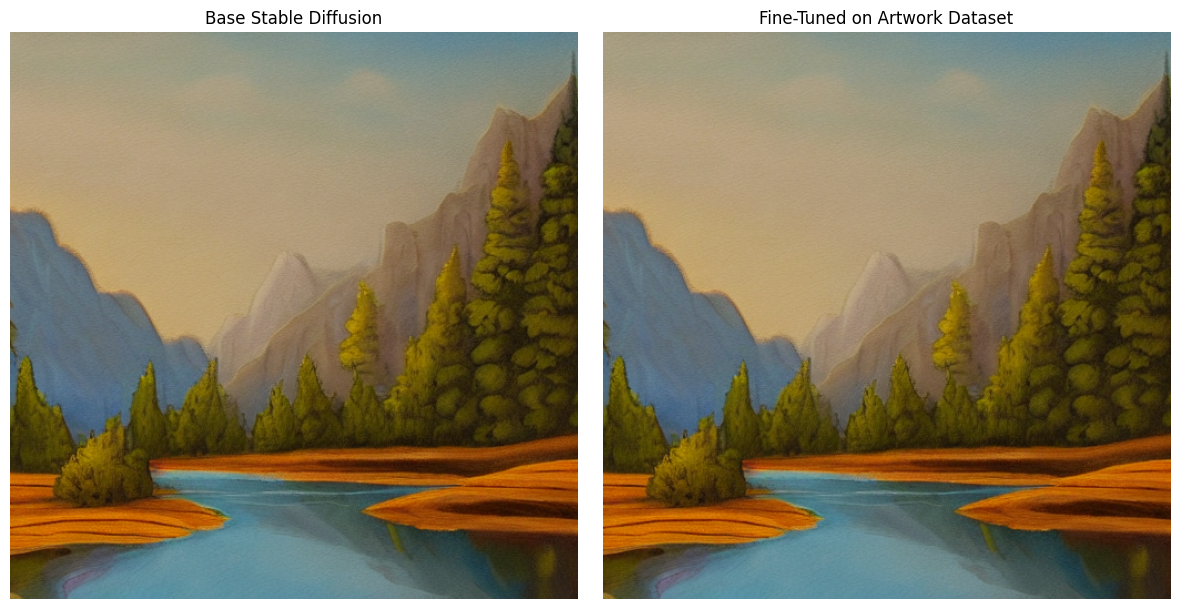

In [ ]:
# ==========================================
# Step 15 : Generate Artwork Images (Base vs Fine-Tuned)
# ==========================================

import matplotlib.pyplot as plt

prompt = "artwork style, a serene landscape painting with mountains and a lake"

generator = torch.Generator(device=device).manual_seed(42)
base_image = base_pipe(prompt, num_inference_steps=30, generator=generator).images[0]

generator = torch.Generator(device=device).manual_seed(42)
finetuned_image = finetuned_pipe(prompt, num_inference_steps=30, generator=generator).images[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(base_image)
axes[0].set_title("Base Stable Diffusion")
axes[0].axis("off")

axes[1].imshow(finetuned_image)
axes[1].set_title("Fine-Tuned on Artwork Dataset")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# ==========================================
# Step 16 : Save Generated Images
# ==========================================

import os

generated_path = "/content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/generated_images"
os.makedirs(generated_path, exist_ok=True)

base_image.save(os.path.join(generated_path, "base_output.png"))
finetuned_image.save(os.path.join(generated_path, "finetuned_output.png"))

print("✅ Generated images saved to:", generated_path)


✅ Generated images saved to: /content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/generated_images


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

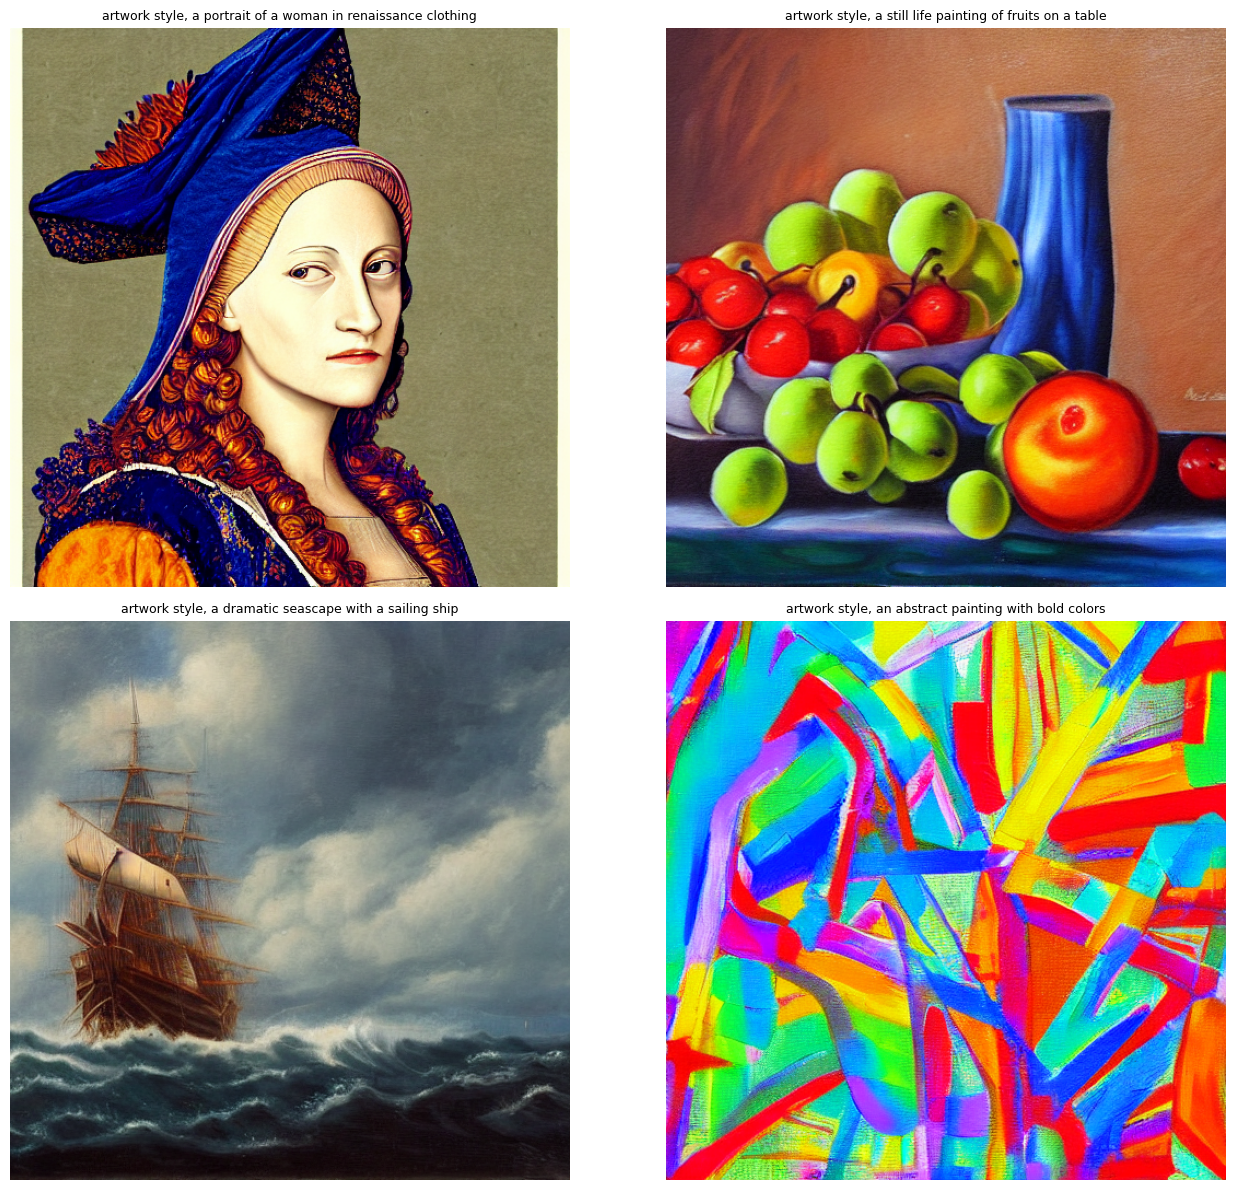

✅ Domain-specific artwork samples generated and saved!


In [ ]:
# ==========================================
# Step 17 : Generate Multiple Domain-Specific Artwork Samples
# ==========================================

prompts = [
    "artwork style, a portrait of a woman in renaissance clothing",
    "artwork style, a still life painting of fruits on a table",
    "artwork style, a dramatic seascape with a sailing ship",
    "artwork style, an abstract painting with bold colors"
]

plt.figure(figsize=(14, 12))

for i, p in enumerate(prompts):
    generator = torch.Generator(device=device).manual_seed(100 + i)
    img = finetuned_pipe(p, num_inference_steps=30, generator=generator).images[0]

    img.save(os.path.join(generated_path, f"sample_{i+1}.png"))

    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(p, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("✅ Domain-specific artwork samples generated and saved!")


In [ ]:
# ==========================================
# Step 18 : Project Summary
# ==========================================

print("=" * 50)
print("PROJECT SUMMARY")
print("=" * 50)
print(f"Base Model          : {MODEL_NAME}")
print(f"Fine-Tuning Method   : LoRA")
print(f"Training Samples     : {len(caption_df)}")
print(f"LoRA Weights Path    : {OUTPUT_DIR}")
print(f"Generated Images Dir : {generated_path}")
print("=" * 50)
print("✅ Stable Diffusion successfully fine-tuned on custom artwork dataset!")


PROJECT SUMMARY
Base Model          : runwayml/stable-diffusion-v1-5
Fine-Tuning Method   : LoRA
Training Samples     : 281
LoRA Weights Path    : /content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/checkpoints/lora-artwork
Generated Images Dir : /content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/generated_images
✅ Stable Diffusion successfully fine-tuned on custom artwork dataset!


Enter a description for the artwork you want to generate: COUPLES SITTING AT BEACH OF SUNSET VIEW SEEING 


  0%|          | 0/30 [00:00<?, ?it/s]

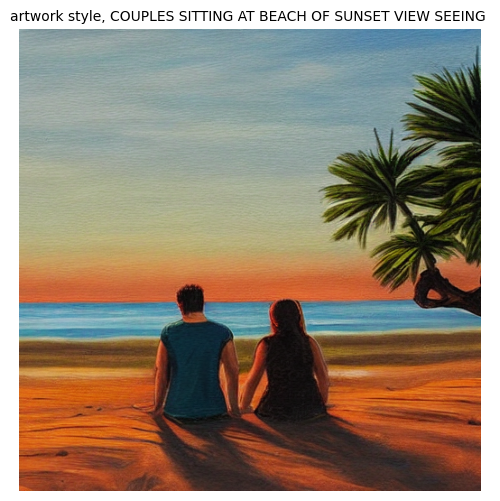

✅ Image generated from your prompt and saved to: /content/drive/MyDrive/Stable_Diffusion_Artwork_FineTuning/generated_images


In [29]:
# ==========================================
# Step 19 : Generate Artwork from Your Own Prompt
# ==========================================

user_prompt = input("Enter a description for the artwork you want to generate: ")

full_prompt = f"artwork style, {user_prompt}"

generator = torch.Generator(device=device).manual_seed(42)
user_image = finetuned_pipe(full_prompt, num_inference_steps=30, generator=generator).images[0]

plt.figure(figsize=(6,6))
plt.imshow(user_image)
plt.title(full_prompt, fontsize=10)
plt.axis("off")
plt.show()

user_image.save(os.path.join(generated_path, "user_prompt_output.png"))
print("✅ Image generated from your prompt and saved to:", generated_path)
